In [233]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/Cinema_Audience_Forecasting_challenge/movie_theater_id_relation/movie_theater_id_relation.csv
/kaggle/input/Cinema_Audience_Forecasting_challenge/date_info/date_info.csv
/kaggle/input/Cinema_Audience_Forecasting_challenge/sample_submission/sample_submission.csv
/kaggle/input/Cinema_Audience_Forecasting_challenge/booknow_theaters/booknow_theaters.csv
/kaggle/input/Cinema_Audience_Forecasting_challenge/cinePOS_booking/cinePOS_booking.csv
/kaggle/input/Cinema_Audience_Forecasting_challenge/cinePOS_theaters/cinePOS_theaters.csv
/kaggle/input/Cinema_Audience_Forecasting_challenge/booknow_visits/booknow_visits.csv
/kaggle/input/Cinema_Audience_Forecasting_challenge/booknow_booking/booknow_booking.csv


In [234]:
import warnings
warnings.filterwarnings('ignore')
import matplotlib.pyplot as plt
import seaborn as sns

# Loading data:

In [235]:
df_booknow_booking = pd.read_csv("/kaggle/input/Cinema_Audience_Forecasting_challenge/booknow_booking/booknow_booking.csv")
df_booknow_theaters = pd.read_csv("/kaggle/input/Cinema_Audience_Forecasting_challenge/booknow_theaters/booknow_theaters.csv")
df_booknow_visits = pd.read_csv("/kaggle/input/Cinema_Audience_Forecasting_challenge/booknow_visits/booknow_visits.csv")
df_cinePOS_booking = pd.read_csv("/kaggle/input/Cinema_Audience_Forecasting_challenge/cinePOS_booking/cinePOS_booking.csv")
df_cinePOS_theaters = pd.read_csv("/kaggle/input/Cinema_Audience_Forecasting_challenge/cinePOS_theaters/cinePOS_theaters.csv")
df_date = pd.read_csv("/kaggle/input/Cinema_Audience_Forecasting_challenge/date_info/date_info.csv")
df_relation = pd.read_csv("/kaggle/input/Cinema_Audience_Forecasting_challenge/movie_theater_id_relation/movie_theater_id_relation.csv")
df_sample_submission = pd.read_csv("/kaggle/input/Cinema_Audience_Forecasting_challenge/sample_submission/sample_submission.csv")

# Merging datasets and creating train and test dataset:

We have been provided with 8 different datasets including the sample submission. I need to create a master dataset by merging different datasets which will serve as the train set. I also need to create a test set from the sample submission provided to us which contains the show date and theater ID of which we need to predict the audience count.

## 1. Train dataset:

In [236]:
df_booknow_visits.head()

,book_theater_id,show_date,audience_count
0,book_00001,2023-01-13,50
1,book_00001,2023-01-14,64
2,book_00001,2023-01-15,58
3,book_00001,2023-01-16,44
4,book_00001,2023-01-18,12


In [237]:
df_sample_submission.head()

,ID,audience_count
0,book_00001_2024-03-01,0
1,book_00001_2024-03-02,0
2,book_00001_2024-03-03,0
3,book_00001_2024-03-04,0
4,book_00001_2024-03-06,0


df_booknow_visits contains "book_theater_id", "show_date" and "audience_count" as columns. We need to predict the audience count for the given theaters and dates provided in the sample submission, therefore, the column "audience_count" is the target, thus, I will treat df_booknow_visits as the main dataset and merge all other datasets into it to create a master dataset which will serve as the train set.

* **Let's start by handling CinePOS.**

In [238]:
df_cinePOS_booking.head()

,cine_theater_id,show_datetime,booking_datetime,tickets_sold
0,cinePOS_00001,2023-01-01 11:00:00,2023-01-01 09:00:00,1
1,cinePOS_00002,2023-01-01 13:00:00,2023-01-01 06:00:00,3
2,cinePOS_00003,2023-01-01 16:00:00,2023-01-01 14:00:00,2
3,cinePOS_00004,2023-01-01 17:00:00,2023-01-01 11:00:00,5
4,cinePOS_00005,2023-01-01 17:00:00,2023-01-01 03:00:00,13


In [239]:
df_relation.head()

,book_theater_id,cine_theater_id
0,book_00509,cinePOS_01261
1,book_00063,cinePOS_02467
2,book_00054,cinePOS_08923
3,book_00094,cinePOS_02479
4,book_00052,cinePOS_06750


df_relation contains the mapping between BookNow and CinePOS theatres meaning that the same theater is present in two platforms with different IDs,

In [240]:
# Merging df_cinePOS_booking which contains all the CinePOS bookings with df_relation using left join 
# such that the bookings with CinePOS theaters are mapped to Booknow theaters
df_cinePOS_booking_new = df_relation.merge(df_cinePOS_booking, on="cine_theater_id", how="left")

# Creating a new column "show_date" by extracting the date present in the "show_datetime"
df_cinePOS_booking_new["show_date"] = pd.to_datetime(df_cinePOS_booking_new["show_datetime"]).dt.date.astype('str')

# Dropping redundant columns "cine_theater_id","booking_datetime","show_datetime"
df_cinePOS_booking_new.drop(["cine_theater_id","booking_datetime","show_datetime"], axis=1, inplace=True)

# Renaming the column "tickets_sold" to "cinePOS_tickets" which will help us identify the platform from which the tickets are booked when we merge the data into a master dataset
df_cinePOS_booking_new.rename(columns={'tickets_sold': 'cinePOS_tickets'}, inplace=True)

# Since, for the same theater, multiple bookings can be made for different shows at different times on the same date
# therefore, I need to aggregate the total number of bookings or tickets sold on a particular date for all the date present in the column "show_date"
df_cinePOS_booking_new = df_cinePOS_booking_new.groupby(["book_theater_id","show_date"])["cinePOS_tickets"].sum().reset_index()

df_cinePOS_booking_new.loc[~(df_cinePOS_booking_new['book_theater_id'].isna())].head()

,book_theater_id,show_date,cinePOS_tickets
0,book_00015,2023-03-28,2
1,book_00015,2023-04-02,2
2,book_00015,2023-04-09,3
3,book_00015,2023-04-12,2
4,book_00015,2023-04-15,2


In [241]:
data = pd.DataFrame({"Null values": df_cinePOS_booking_new.isna().sum(),
                    "Percentage": ((df_cinePOS_booking_new.isna().sum()/df_cinePOS_booking_new.shape[0])*100).astype(str)+"%"})
data

,Null values,Percentage
book_theater_id,0,0.0%
show_date,0,0.0%
cinePOS_tickets,0,0.0%


* **Handling Booknow.**

In [242]:
df_booknow_booking.head()

,book_theater_id,show_datetime,booking_datetime,tickets_booked
0,book_00244,2023-01-01 19:00:00,2023-01-01 16:00:00,1
1,book_00740,2023-01-01 19:00:00,2023-01-01 19:00:00,3
2,book_00740,2023-01-01 19:00:00,2023-01-01 19:00:00,6
3,book_00244,2023-01-01 20:00:00,2023-01-01 16:00:00,2
4,book_00151,2023-01-01 20:00:00,2023-01-01 01:00:00,5


In [243]:
df_booknow_booking_new = df_booknow_booking.copy() # making a copy of the original dataset

# Creating a new column "show_date" by extracting the date present in the "show_datetime"
df_booknow_booking_new["show_date"] = pd.to_datetime(df_booknow_booking["show_datetime"]).dt.date.astype('str')

# Dropping redundant columns "booking_datetime","show_datetime"
df_booknow_booking_new.drop(["show_datetime", "booking_datetime"], axis=1, inplace=True)

# Renaming the column "tickets_booked" to "booknow_tickets" which will help us identify the platform from which the tickets are booked when we merge the data into a master dataset
df_booknow_booking_new.rename(columns={"tickets_booked": "booknow_tickets"}, inplace=True)

# Since, for the same theater, multiple bookings can be made for different shows at different times on the same date
# therefore, we need to aggregate the total number of bookings or tickets sold on a particular date for all the date present in the column "show_date"
df_booknow_booking_new = df_booknow_booking_new.groupby(["book_theater_id","show_date"])["booknow_tickets"].sum().reset_index()

df_booknow_booking_new.head()

,book_theater_id,show_date,booknow_tickets
0,book_00004,2023-02-27,12
1,book_00013,2023-01-04,2
2,book_00013,2023-01-08,3
3,book_00013,2023-01-09,25
4,book_00013,2023-01-10,5


In [244]:
data = pd.DataFrame({"Null values": df_booknow_booking_new.isna().sum(),
                    "Percentage": ((df_booknow_booking_new.isna().sum()/df_booknow_booking_new.shape[0])*100).astype(str)+"%"})
data

,Null values,Percentage
book_theater_id,0,0.0%
show_date,0,0.0%
booknow_tickets,0,0.0%


* **Creation of train dataset.**

In [245]:
df_date.head()

,show_date,day_of_week
0,2023-01-01,Sunday
1,2023-01-02,Monday
2,2023-01-03,Tuesday
3,2023-01-04,Wednesday
4,2023-01-05,Thursday


In [246]:
df_booknow_theaters.head()

,book_theater_id,theater_type,theater_area,latitude,longitude
0,book_00093,Drama,Area_001,22.619233,78.113017
1,book_00078,Drama,Area_001,22.619233,78.113017
2,book_00291,Drama,Area_001,22.619233,78.113017
3,book_00258,Drama,Area_001,22.619233,78.113017
4,book_00212,Drama,Area_002,23.004410,79.934515


In [247]:
# Merging df_booknow_visits with two new dataset created which are df_cinePOS_booking_new and df_booknow_booking_new
df_train = df_booknow_visits.merge(df_booknow_booking_new, on=["book_theater_id","show_date"], how="left")
df_train = df_train.merge(df_cinePOS_booking_new, on=["book_theater_id","show_date"], how="left")

# Merging new dataset df_train with df_date which contains the information about the day of the week for the dates present in the column "show_date"
df_train = df_train.merge(df_date, on="show_date", how="left")

# Merging df_train with df_booknow_theaters which contains the information about the theaters
df_train = df_train.merge(df_booknow_theaters, on="book_theater_id", how="left")

# Thus, df_train is the master dataset which will serve as the train set
display(df_train[~(df_train["booknow_tickets"].isna()) & ~(df_train["cinePOS_tickets"].isna())].head())
print(f"Shape of the train set: {df_train.shape}")

,book_theater_id,show_date,audience_count,booknow_tickets,cinePOS_tickets,day_of_week,theater_type,theater_area,latitude,longitude
4041,book_00015,2023-10-27,96,12.0,2.0,Friday,Drama,Area_023,22.636222,78.170501
4042,book_00015,2023-10-28,50,4.0,2.0,Saturday,Drama,Area_023,22.636222,78.170501
4043,book_00015,2023-10-29,84,17.0,28.0,Sunday,Drama,Area_023,22.636222,78.170501
4045,book_00015,2023-11-01,152,74.0,3.0,Wednesday,Drama,Area_023,22.636222,78.170501
4048,book_00015,2023-11-04,10,11.0,7.0,Saturday,Drama,Area_023,22.636222,78.170501


Shape of the train set: (214046, 10)


## 2. Test dataset:

In [248]:
df_sample_submission.head()

,ID,audience_count
0,book_00001_2024-03-01,0
1,book_00001_2024-03-02,0
2,book_00001_2024-03-03,0
3,book_00001_2024-03-04,0
4,book_00001_2024-03-06,0


"df_sample_submission" contains column "ID" which contains the information about the theater IDs and the show dates, therefore, I need to extract this information into two new columns. I also need to add columns like "booknow_tickets", "cinePOS_tickets", "day_of_week", "theater_type", "theater_area", "latitude", "longitude", such that the features/columns present in the train and test set are the same.

In [249]:
# creating a copy of the sample submission excluding column "audience_count"
df_test = df_sample_submission.copy()
df_test = df_test.drop("audience_count", axis=1)

# Extracting theater IDs and show dates into two new columns "book_theater_id" and "show_date"
df_test["book_theater_id"] = df_test["ID"].str.slice(0,-11)
df_test["show_date"] = df_test["ID"].str.slice(-10,)

# Dropping column "ID"
df_test.drop("ID", axis=1, inplace=True)

# In order to add columns "booknow_tickets" and "cinePOS_tickets", I can do left join with df_booknow_booking_new and df_cinePOS_booking_new
df_test = df_test.merge(df_booknow_booking_new, how="left", on=["book_theater_id", "show_date"])
df_test = df_test.merge(df_cinePOS_booking_new, how="left", on=["book_theater_id", "show_date"])

# Merging df_test with df_date which contains the information about the day of the week for the dates present in the column "show_date"
df_test = df_test.merge(df_date, on="show_date", how="left")

# Merging df_test with df_booknow_theaters which contains the information about the theaters
df_test = df_test.merge(df_booknow_theaters, on="book_theater_id", how="left")

display(df_test.head())
print(f"Shape of test set: {df_test.shape}")

,book_theater_id,show_date,booknow_tickets,cinePOS_tickets,day_of_week,theater_type,theater_area,latitude,longitude
0,book_00001,2024-03-01,NaN,NaN,Friday,Drama,Area_002,23.00441,79.934515
1,book_00001,2024-03-02,NaN,NaN,Saturday,Drama,Area_002,23.00441,79.934515
2,book_00001,2024-03-03,NaN,NaN,Sunday,Drama,Area_002,23.00441,79.934515
3,book_00001,2024-03-04,NaN,NaN,Monday,Drama,Area_002,23.00441,79.934515
4,book_00001,2024-03-06,NaN,NaN,Wednesday,Drama,Area_002,23.00441,79.934515


Shape of test set: (38062, 9)


# Identifying datatypes of columns:

In [250]:
print('Datatypes of Train data with additional information about the columns:')
df_train.info()

Datatypes of Train data with additional information about the columns:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 214046 entries, 0 to 214045
Data columns (total 10 columns):
 #   Column           Non-Null Count   Dtype  
---  ------           --------------   -----  
 0   book_theater_id  214046 non-null  object 
 1   show_date        214046 non-null  object 
 2   audience_count   214046 non-null  int64  
 3   booknow_tickets  21041 non-null   float64
 4   cinePOS_tickets  11150 non-null   float64
 5   day_of_week      214046 non-null  object 
 6   theater_type     80150 non-null   object 
 7   theater_area     80150 non-null   object 
 8   latitude         80150 non-null   float64
 9   longitude        80150 non-null   float64
dtypes: float64(4), int64(1), object(5)
memory usage: 16.3+ MB


In [251]:
print('Datatypes of Test data with additional information about the columns:')
df_test.info()

Datatypes of Test data with additional information about the columns:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 38062 entries, 0 to 38061
Data columns (total 9 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   book_theater_id  38062 non-null  object 
 1   show_date        38062 non-null  object 
 2   booknow_tickets  0 non-null      float64
 3   cinePOS_tickets  0 non-null      float64
 4   day_of_week      38062 non-null  object 
 5   theater_type     14606 non-null  object 
 6   theater_area     14606 non-null  object 
 7   latitude         14606 non-null  float64
 8   longitude        14606 non-null  float64
dtypes: float64(4), object(5)
memory usage: 2.6+ MB


In [252]:
# Changing the datatype of show_date column to datetime

df_train["show_date"] = pd.to_datetime(df_train["show_date"])
df_test["show_date"] = pd.to_datetime(df_test["show_date"])

# Descriptive statistics of numerical columns:

In [253]:
print('Descriptive statistics of Train data')
df_train.select_dtypes(include="number").describe()

Descriptive statistics of Train data


,audience_count,booknow_tickets,cinePOS_tickets,latitude,longitude
count,214046.000000,21041.000000,11150.000000,80150.000000,80150.000000
mean,41.616568,13.675776,6.704215,23.108170,78.936323
std,32.834918,18.599312,7.521122,1.019523,1.490336
min,2.000000,1.000000,1.000000,22.025970,76.173250
25%,18.000000,5.000000,2.000000,22.613688,77.970347
50%,34.000000,10.000000,4.000000,23.004410,79.895175
75%,58.000000,18.000000,8.000000,23.018784,79.935314
max,1350.000000,1633.000000,157.000000,26.349436,81.743235


In [254]:
print('Descriptive statistics of Test data')
df_test[["latitude","longitude"]].describe() 

Descriptive statistics of Test data


,latitude,longitude
count,14606.000000,14606.000000
mean,23.114919,78.946891
std,1.022010,1.469916
min,22.025970,76.173250
25%,22.616480,78.113017
50%,23.004410,79.895175
75%,23.018784,79.935314
max,26.349436,81.743235


# Identifying and handling the missing values:

## 1. Identifying missing values:

In [255]:
print('Missing values in Train data')
data = pd.DataFrame(df_train.isna().sum(), columns=["Null values"])
rows = df_train.shape[0]
data["Percentage"] = round((data["Null values"]/rows)*100, 2).astype(str)+"%"
data

Missing values in Train data


,Null values,Percentage
book_theater_id,0,0.0%
show_date,0,0.0%
audience_count,0,0.0%
booknow_tickets,193005,90.17%
cinePOS_tickets,202896,94.79%
day_of_week,0,0.0%
theater_type,133896,62.55%
theater_area,133896,62.55%
latitude,133896,62.55%
longitude,133896,62.55%


In [256]:
print('Missing values in Test data')
data = pd.DataFrame(df_test.isna().sum(), columns=["Null values"])
rows = df_test.shape[0]
data["Percentage"] = round((data["Null values"]/rows)*100, 2).astype(str)+"%"
data

Missing values in Test data


,Null values,Percentage
book_theater_id,0,0.0%
show_date,0,0.0%
booknow_tickets,38062,100.0%
cinePOS_tickets,38062,100.0%
day_of_week,0,0.0%
theater_type,23456,61.63%
theater_area,23456,61.63%
latitude,23456,61.63%
longitude,23456,61.63%


## 2. Handling missing values:

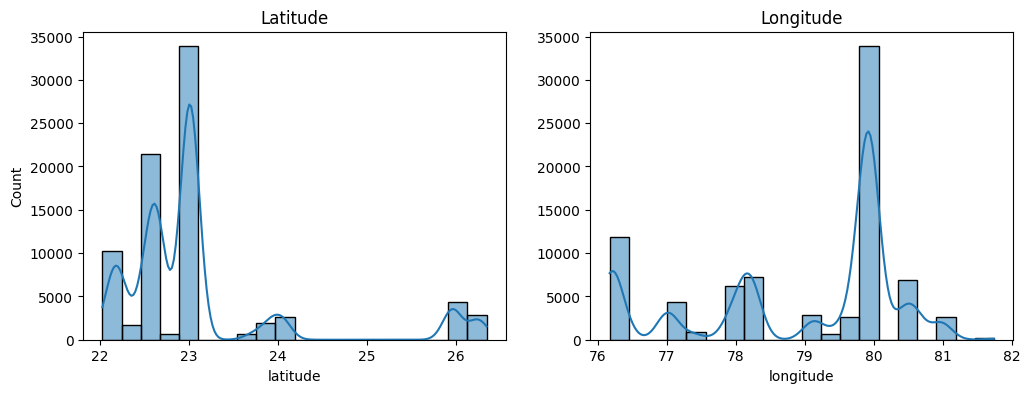

In [257]:
fig, axis = plt.subplots(1,2, figsize=(12,4))

sns.histplot(data=df_train, x="latitude", bins=20, ax=axis[0], kde=True).set_title("Latitude")

sns.histplot(data=df_train, x="longitude", bins=20, ax=axis[1], kde=True).set_title("Longitude")
axis[1].set_ylabel("")
plt.show()

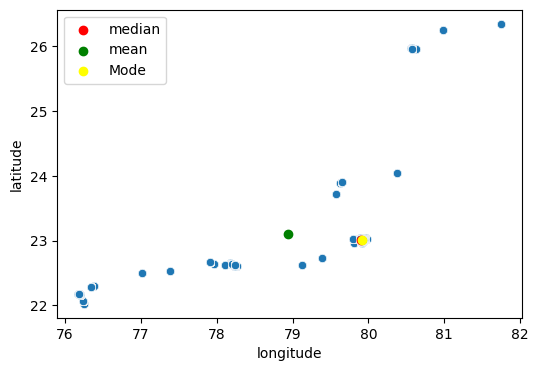

In [258]:
plt.figure(figsize=(6,4))
sns.scatterplot(data=df_train, x="longitude", y="latitude")
plt.scatter(x=df_train["longitude"].median(), y=df_train["latitude"].median(), color="red", label="median")
plt.scatter(x=df_train["longitude"].mean(), y=df_train["latitude"].mean(), color="green", label="mean")
plt.scatter(x=df_train["longitude"].mode(), y=df_train["latitude"].mode(), color="yellow", label="Mode")
plt.legend()
plt.show()

* Median and mode are approximately similar to each other.
* Presence of possible outliers.

In [259]:
from sklearn.impute import SimpleImputer

# Replacing missing values in booknow and cinePOS tickets 0
df_train[["booknow_tickets", "cinePOS_tickets"]] = df_train[["booknow_tickets", "cinePOS_tickets"]].fillna(0)
df_test[["booknow_tickets", "cinePOS_tickets"]] = df_test[["booknow_tickets", "cinePOS_tickets"]].fillna(0)

# Replacing missing values in "theater_type" and "theater_area" with value "Unknown"
df_train[["theater_type", "theater_area"]] = df_train[["theater_type", "theater_area"]].fillna("Unknown")
df_test[["theater_type", "theater_area"]] = df_test[["theater_type", "theater_area"]].fillna("Unknown")

# Replacing missing values in "latitude" and "longitude" with median
SI = SimpleImputer(strategy="median")
df_train[["latitude", "longitude"]] = SI.fit_transform(df_train[["latitude", "longitude"]])
df_test[["latitude", "longitude"]] = SI.transform(df_test[["latitude", "longitude"]])


In [260]:
print('Missing values in Train data')
df_train.isna().sum()

Missing values in Train data


book_theater_id    0
show_date          0
audience_count     0
booknow_tickets    0
cinePOS_tickets    0
day_of_week        0
theater_type       0
theater_area       0
latitude           0
longitude          0
dtype: int64

In [261]:
print('Missing values in Test data')
df_test.isna().sum()

Missing values in Test data


book_theater_id    0
show_date          0
booknow_tickets    0
cinePOS_tickets    0
day_of_week        0
theater_type       0
theater_area       0
latitude           0
longitude          0
dtype: int64

# Identifying and handling duplicates:

In [262]:
train_duplicates = df_train.duplicated().sum()
if train_duplicates == 0:
    print(f'{train_duplicates} duplicates found in Train data.', end="\n\n")
else:
    print(f'{train_duplicates} duplicates found in Train data.')
    df_train = df_train.drop_duplicates(keep="first")
    print(f'Duplicates removed successfully.', end="\n\n")

test_duplicates = df_test.duplicated().sum()
if test_duplicates == 0:
    print(f'{test_duplicates} duplicates found in test data.', end="\n\n")
else:
    print(f'{test_duplicates} duplicates found in test data.')
    df_test = df_test.drop_duplicates(keep="first")
    print(f'Duplicates removed successfully.', end="\n\n")

10 duplicates found in Train data.
Duplicates removed successfully.

0 duplicates found in test data.



# Identifying and handling outliers:

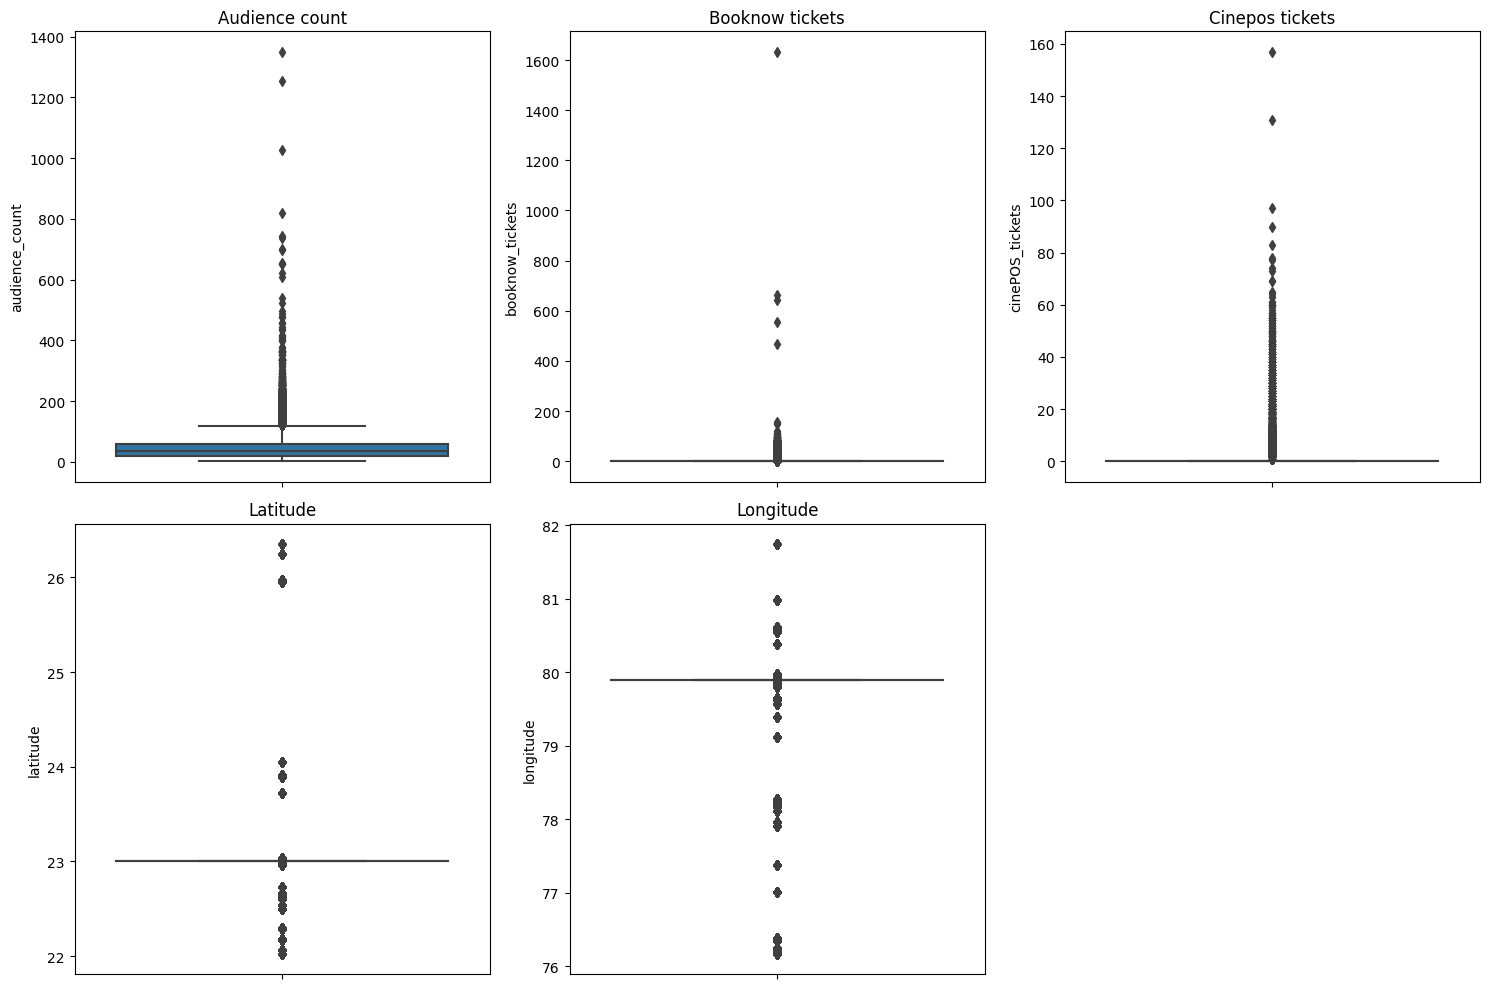

In [263]:
# Visualizing outliers using boxplot

plots = df_train.select_dtypes(include="number").columns.tolist()

plt.figure(figsize=(15,10))
for i in range(5):
    plt.subplot(2,3,i+1)
    sns.boxplot(data=df_train, y=plots[i])
    title = " ".join(plots[i].split("_"))
    plt.title(title.capitalize())
plt.tight_layout()
plt.show()

In [264]:
# IQR method

def outliers(df, col):
    
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - (1.5*IQR)
    upper = Q3 + (1.5*IQR)

    return df.loc[(df[col]<lower) | (df[col]>upper)].shape[0]


columns = {"Latitude": "latitude", 
           "Longitude": "longitude", 
           "Booknow tickets": "booknow_tickets",
           "CinePOS tickets": "cinePOS_tickets",
           "Audience count": "audience_count"}

rows = df_train.shape[0]
outlier_counts = []
outlier_names = []

for key, value in columns.items():
    counts = outliers(df_train, value)
    outlier_counts.append(counts)
    outlier_names.append(key)

data = pd.DataFrame({
    "Outliers": outlier_counts
}, index = outlier_names)

data["Percentage"] = round((data["Outliers"]/rows*100), 2).astype(str)+"%"
data

,Outliers,Percentage
Latitude,76580,35.78%
Longitude,79303,37.05%
Booknow tickets,21041,9.83%
CinePOS tickets,11150,5.21%
Audience count,5589,2.61%


* Since, latitude and longitude column contains huge amount of outliers, I decided to drop it after extracting features from it.
* I decided to retain booknow and cinePOS tickets column and use Robust scaler to handle the outliers.
* I decided to retain audience count as it is.

# Visualizations:

## 1. Histogram of target Audience Count:

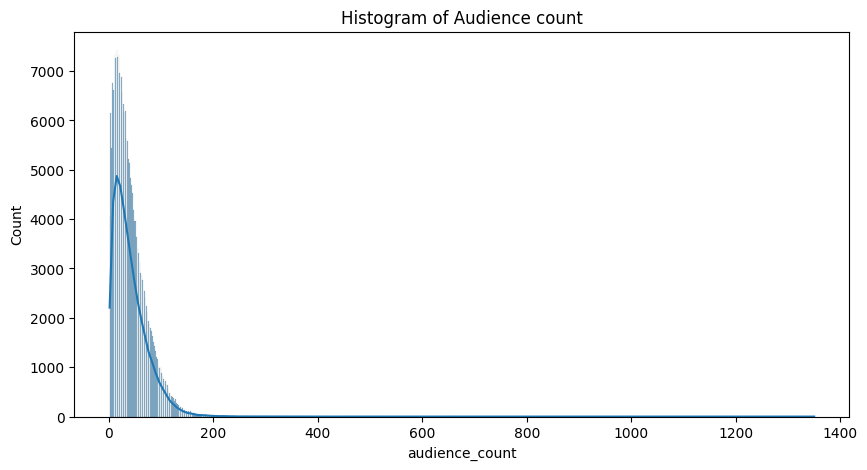

In [265]:
plt.figure(figsize=(10,5))
sns.histplot(df_train["audience_count"], kde=True)
plt.title("Histogram of Audience count")
plt.show()

* The audience count is right skewed, this could be due to blockbuster events, holidays, etc.

## 2. Time series trend of average daily cinema audience attendance:

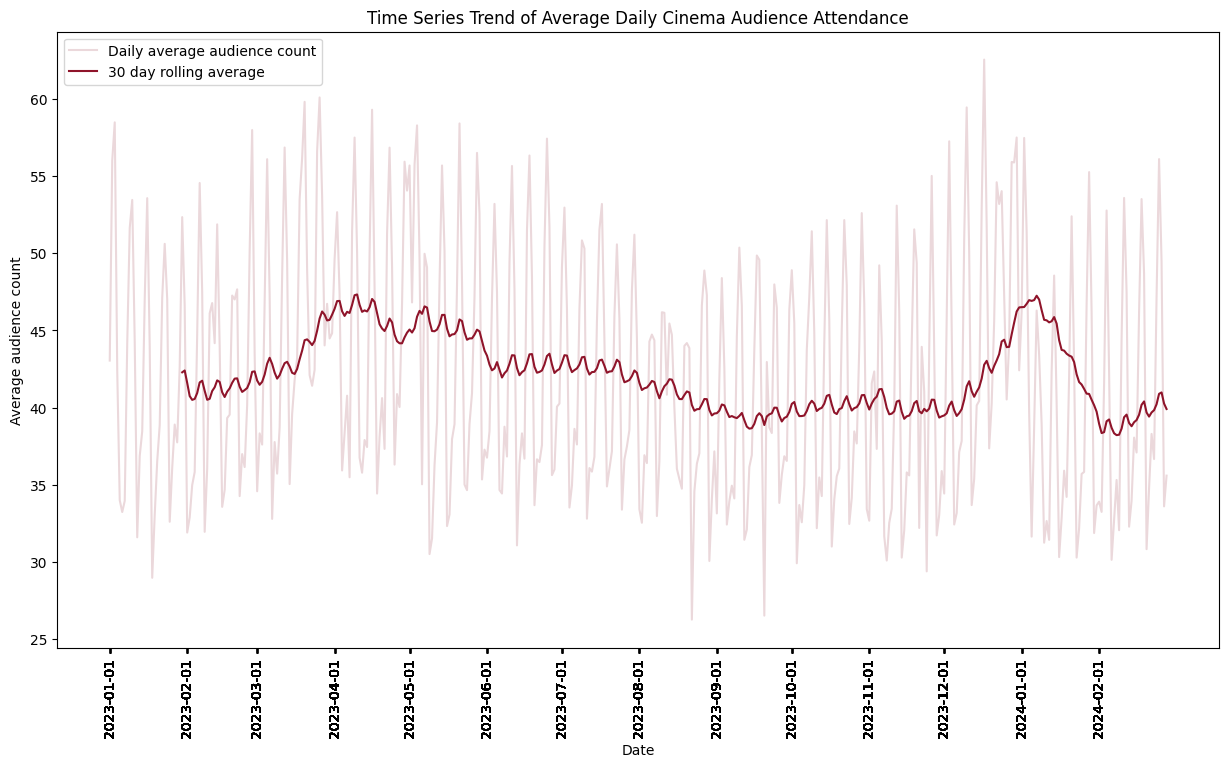

In [266]:
data = df_train.groupby("show_date")["audience_count"].mean().reset_index()
data["show_date"] = pd.to_datetime(data["show_date"])
data["rolling_avg"] = data["audience_count"].rolling(window=30).mean()

plt.figure(figsize=(15, 8))
sns.lineplot(data=data, x="show_date", y="audience_count", color="#ebd8db", label="Daily average audience count")
sns.lineplot(data=data, x="show_date", y="rolling_avg", color="#8f142a", label="30 day rolling average")
plt.xlabel("Date")
plt.ylabel("Average audience count")
plt.title("Time Series Trend of Average Daily Cinema Audience Attendance")
plt.xticks(data["show_date"].astype(str).str.slice(0,7), rotation=90)
plt.show()

* From the 30 day rolling average it seems that the overall daily average audience attendance across all theaters was slightly lower at the beginning of 2024 as compared to the beginning of 2023.
* The rapid up and down in daily average audience attendance shows a very strong weekly seasonal pattern. Attendance clearly spikes during weekends and drops dramatically during the weekdays.
* The short-term spikes above the rolling trend line could be due to blockbuster events, holidays, etc.

## 3. Distribution of average audience attendance by day of the week:

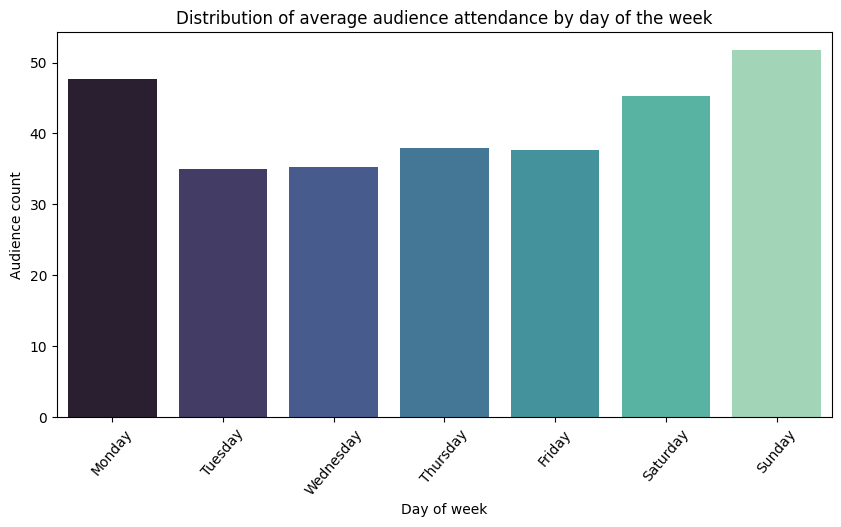

In [267]:
data = df_train.groupby("day_of_week")["audience_count"].mean().reset_index()
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

plt.figure(figsize=(10,5))
sns.barplot(data=data, x="day_of_week", y="audience_count", palette="mako", order=day_order)
plt.title("Distribution of average audience attendance by day of the week")
plt.xlabel("Day of week")
plt.ylabel("Audience count")
plt.xticks(rotation=50)
plt.show()

* This plot clearly show the weekly seasional pattern observed in the trends plot above with attendance spiking during weekends including Mondays and dropping during the weekdays.

## 4. Distribution of market share between Booknow and CinePOS:

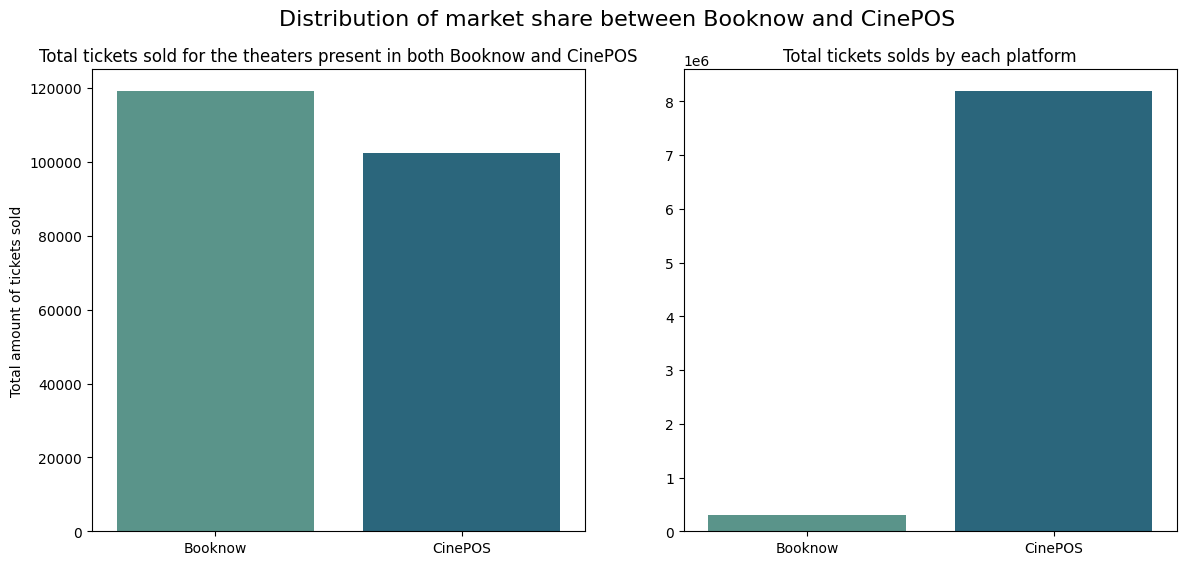

In [268]:
# Total tickets sold for the theaters present in both Booknow and CinePOS
data = df_relation.merge(df_booknow_booking.drop(["show_datetime", "booking_datetime"], axis=1).groupby("book_theater_id")["tickets_booked"].sum().reset_index(), how="left", on="book_theater_id")
data = data.merge(df_cinePOS_booking.drop(["show_datetime", "booking_datetime"], axis=1).groupby("cine_theater_id")["tickets_sold"].sum().reset_index(), how="left", on="cine_theater_id")
data.rename(columns={"tickets_booked": "booknow_tickets", "tickets_sold": "cinePOS_tickets"}, inplace=True)
data.fillna(0.0, inplace=True)

total_booknow_tickets = data["booknow_tickets"].sum()
total_cinePOS_tickets = data["cinePOS_tickets"].sum()

# Total tickets sold by each platform
total_booknow_tickets_all = df_booknow_booking["tickets_booked"].sum()
total_cinePOS_tickets_all = df_cinePOS_booking["tickets_sold"].sum()


fig, axis = plt.subplots(1, 2, figsize=(14,6))
sns.barplot(x=["Booknow", "CinePOS"], y=[total_booknow_tickets, total_cinePOS_tickets], ax=axis[0], palette="crest").set_title("Total tickets sold for the theaters present in both Booknow and CinePOS")
sns.barplot(x=["Booknow", "CinePOS"], y=[total_booknow_tickets_all, total_cinePOS_tickets_all], ax=axis[1], palette="crest").set_title("Total tickets solds by each platform")
fig.suptitle("Distribution of market share between Booknow and CinePOS", fontsize="16")
axis[0].set_ylabel("Total amount of tickets sold")
axis[1].set_ylabel("")
plt.show()

* CinePOS is the overwhelmingly dominant source of ticket sales globally.
* While CinePOS dominates globally, for the specific subset of theaters where both platforms are available and recorded in the relation file, BookNow is the slightly preferred booking platform.

## 5. Distribution of Audience attendance by theater type:

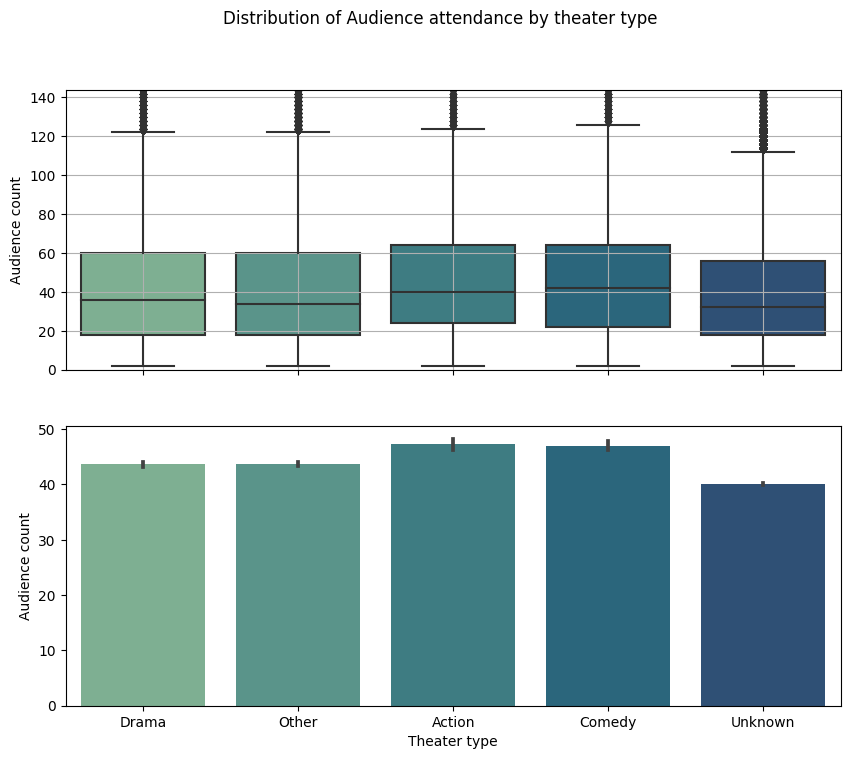

In [269]:
fig, axis = plt.subplots(2,1, figsize=(10,8))
sns.boxplot(data=df_train, x="theater_type", y="audience_count", palette="crest", ax=axis[0])
sns.barplot(data=df_train, x="theater_type", y="audience_count", palette="crest", ax=axis[1])
fig.suptitle("Distribution of Audience attendance by theater type")
axis[1].set_xlabel("Theater type")
axis[0].set_xlabel("")
axis[0].set_ylabel("Audience count")
axis[1].set_ylabel("Audience count")
axis[0].set_ylim(0, df_train['audience_count'].quantile(0.99))
axis[0].set_xticklabels([])
axis[0].grid(True)
plt.show()

In [270]:
theater_type = df_train["theater_type"].unique().tolist()
data = pd.DataFrame({"Median": df_train.groupby("theater_type")["audience_count"].median()})
data["IQR"] = df_train.groupby("theater_type")["audience_count"].quantile(0.75) - df_train.groupby("theater_type")["audience_count"].quantile(0.25)
data["Max_value"] = df_train.groupby("theater_type")["audience_count"].max()
data["Min_value"] = df_train.groupby("theater_type")["audience_count"].min()
data["Mean"] = df_train.groupby("theater_type")["audience_count"].mean()

data

,Median,IQR,Max_value,Min_value,Mean
theater_type,,,,,
Action,40.0,40.0,1350,2,47.242530
Comedy,42.0,42.0,240,2,47.012019
Drama,36.0,42.0,656,2,43.630188
Other,34.0,42.0,610,2,43.718884
Unknown,32.0,38.0,1254,2,40.062230


* Comedy theaters have the highest median audience attendance. Action theaters follow closely. The Drama, Other, and Unknown categories show lower median attendance, with "Unknown" having the lowest median.
* For Drama, Comedy and Other, the distribution (IQR) is widest, meaning the three types share the highest degree of variability in their core attendance data.
* All categories show numerous outliers stretching far above the upper whisker. These likely represent blockbuster movie weekends, holidays, or special events which draw audiences far larger than the typical 75th percentile.
* Action theaters hold the record for the absolute highest attendance day (1,350), making them the most prone to catastrophic outliers.
* Comedy has the lowest max value (240) among the four known types, meaning while its typical attendance varies wildly (high IQR), its absolute peaks are surprisingly capped.

## 6. Distribution of Audience attendace by theater area:

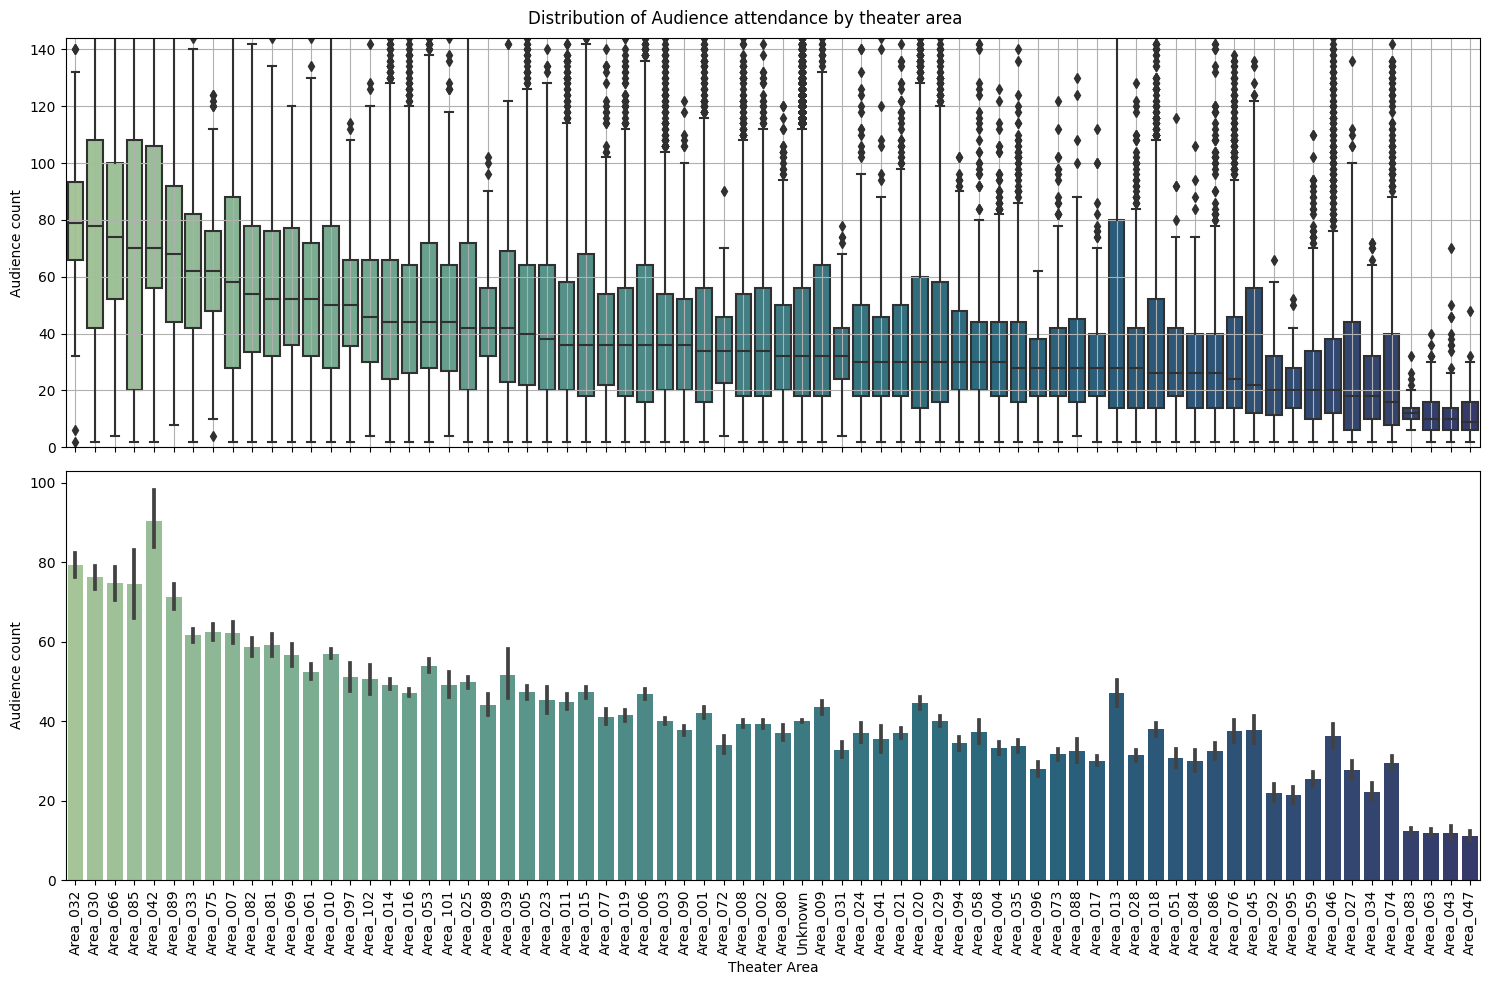

In [271]:
area_order = df_train.groupby("theater_area")["audience_count"].median().sort_values(ascending=False).index

fig, axis = plt.subplots(2,1, figsize=(15,10))
sns.boxplot(data=df_train, x="theater_area", y="audience_count", palette="crest", ax=axis[0], order=area_order)
sns.barplot(data=df_train, x="theater_area", y="audience_count", palette="crest", ax=axis[1], order=area_order)
fig.suptitle("Distribution of Audience attendance by theater area")
axis[1].set_xlabel("Theater Area")
axis[0].set_xlabel("")
axis[0].set_ylabel("Audience count")
axis[1].set_ylabel("Audience count")
axis[0].set_ylim(0, df_train['audience_count'].quantile(0.99))
axis[0].set_xticklabels([])
axis[0].grid(True)
axis[1].tick_params(axis='x', rotation=90)
plt.tight_layout()
plt.show()

In [272]:
theater_area = df_train["theater_area"].unique().tolist()
data = pd.DataFrame({"Median": df_train.groupby("theater_area")["audience_count"].median(),
                    "Mean": df_train.groupby("theater_area")["audience_count"].mean()},
                   index=theater_area)

theater_area_order = data.sort_values(["Median", "Mean"], ascending=[False, False]).index.to_list()
data.sort_values(["Median", "Mean"], ascending=[False, False]).head(10)

,Median,Mean
Area_032,79.0,79.400000
Area_030,78.0,76.248000
Area_066,74.0,74.706468
Area_042,70.0,90.523962
Area_085,70.0,74.545455
Area_089,68.0,71.400000
Area_075,62.0,62.426859
Area_033,62.0,61.609240
Area_007,58.0,62.268041
Area_082,54.0,58.588235


* The areas plotted on the far left of the graph represent theaters that have the highest typical audience attendance (highest median). These are the most valuable market segments for consistent, day-to-day sales.
* The areas on the far right have the lowest median attendance. These theaters represent lower-traffic suburban or niche markets.

## 7. Correlation Matrix of numerical features:

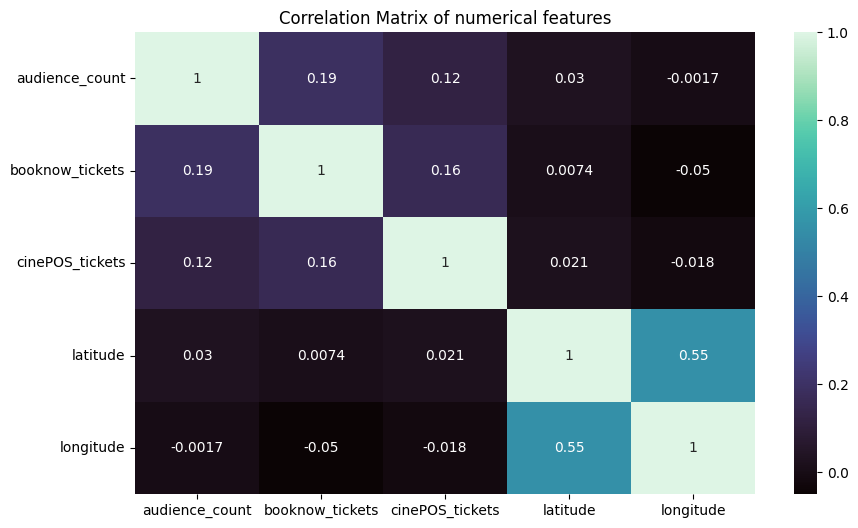

In [273]:
plt.figure(figsize=(10,6))
sns.heatmap(data=df_train.select_dtypes(include="number").corr(), annot=True, cmap="mako")
plt.title("Correlation Matrix of numerical features")
plt.show()

* Both the raw latitude and longitude coordinates show correlations close to zero. They have no linear predictive power on audience size.
* Booknow and CinePOS tickets have a weak positive correlation of 0.19 and 0.12 with audience count.

# Feature Engineering:

## Extracting information from "show_date" column:

In [274]:
def time_features(df):
    df = df.copy()
    df["month"] = df["show_date"].dt.month
    df["day"] = df["show_date"].dt.day
    df["week_of_year"] = df["show_date"].dt.isocalendar().week.astype(int)

    # if day of week is either sat, sun or mon then 1 else 0
    df["high_attendance_days"] = df["day_of_week"].isin(["Saturday", "Sunday", "Monday"]).astype(int)
    
    return df

df_train = time_features(df_train)
df_test = time_features(df_test)

df_train.head()

,book_theater_id,show_date,audience_count,booknow_tickets,cinePOS_tickets,day_of_week,theater_type,theater_area,latitude,longitude,month,day,week_of_year,high_attendance_days
0,book_00001,2023-01-13,50,0.0,0.0,Friday,Drama,Area_002,23.00441,79.934515,1,13,2,0
1,book_00001,2023-01-14,64,0.0,0.0,Saturday,Drama,Area_002,23.00441,79.934515,1,14,2,1
2,book_00001,2023-01-15,58,0.0,0.0,Sunday,Drama,Area_002,23.00441,79.934515,1,15,2,1
3,book_00001,2023-01-16,44,0.0,0.0,Monday,Drama,Area_002,23.00441,79.934515,1,16,3,1
4,book_00001,2023-01-18,12,0.0,0.0,Wednesday,Drama,Area_002,23.00441,79.934515,1,18,3,0


## Total tickets booked:

In [275]:
# Adding the booknow and cinePOS tickets
df_train["tickets_booked"] = df_train["booknow_tickets"] + df_train["cinePOS_tickets"]

# Since, the number of tickets sold for future dates are zero
df_test["tickets_booked"] = 0

# Dropping the booknow and cinePOS tickets columns because it's not needed anymore
df_train.drop(columns=["booknow_tickets", "cinePOS_tickets"], inplace=True)
df_test.drop(columns=["booknow_tickets", "cinePOS_tickets"], inplace=True)

## Identifying theater areas with highest audience count:

In [276]:
# The goal is to average the audience count of each theater area
# and identifying top 25 percentile theater areas with respect to average audience attendance

# Calculating mean for every theater
df_theater_area = df_train.groupby("theater_area")["audience_count"].mean().reset_index()

# Calculating the 75th percentile
Q3 = df_theater_area["audience_count"].quantile(0.75)

# Identifying theater areas which has average audience count above 75th percentile
theater_area = df_theater_area.loc[df_theater_area["audience_count"] > Q3, "theater_area"]

# Initializaing the columns max_area
df_train["max_area"] = 0
df_test["max_area"] = 0

# If the theater area is among top 25th percentile then setting max_area to 1
df_train.loc[df_train["theater_area"].isin(theater_area), "max_area"] = 1
df_test.loc[df_test["theater_area"].isin(theater_area), "max_area"] = 1

## Identifying events:

In [277]:
# The goal is to average the audience count for each of the show_date
# and identifying the month and day combination which is among the top 25 percentile with respect to average audience attendance

# Calculating mean for every date
df_holidays = df_train.groupby("show_date")["audience_count"].mean().reset_index()

# Calculating the 75th percentile
high_attendance = df_holidays["audience_count"].quantile(0.75)

# Identifying the month and day combination which has average audience count above 75th percentile
high_attendance_dates = df_holidays.loc[df_holidays["audience_count"] > high_attendance, "show_date"].astype(str).str.slice(5,10).unique()

# Adding a new column which contains all the combinations of month and day
df_train["MM_DD"] = df_train["show_date"].astype(str).str.slice(5,10)
df_test["MM_DD"] = df_test["show_date"].astype(str).str.slice(5,10)

# Initializing the event columns
df_train["event"] = 0
df_test["event"] = 0

# If the month and day combination is among top 25th percentile then setting event to 1 
df_train.loc[df_train["MM_DD"].isin(high_attendance_dates), "event"] = 1
df_test.loc[df_test["MM_DD"].isin(high_attendance_dates), "event"] = 1

# Dropping the column which had the day and month combination
df_train.drop(columns="MM_DD", inplace=True)
df_test.drop(columns="MM_DD", inplace=True)

## Identifying locations with highest audience attendance:

In [278]:
# The goal is to average the audience count for each of the combination of latitude and longitude
# and identifying the latitude and longitude combination which is among the top 25 percentile with respect to average audience attendance

# Calculating mean for every combination of latitude and longitude
data = df_train.groupby(["latitude", "longitude"])["audience_count"].mean().reset_index()

# Calculating the 75th percentile
Q3 = data["audience_count"].quantile(0.75)

# Identifying the latitude and longitude combination which has average audience count above 75th percentile
df_loc = data.loc[data["audience_count"]>Q3, ["latitude", "longitude"]]

# Adding a new column which contains all the combinations of latitude and longitude
df_loc["tup_loc"] = df_loc["latitude"].astype(str)+"_"+df_loc["longitude"].astype(str)
tup_loc = df_loc["tup_loc"].unique()
df_train["tup_loc"] = df_train["latitude"].astype(str)+"_"+df_train["longitude"].astype(str)
df_test["tup_loc"] = df_test["latitude"].astype(str)+"_"+df_test["longitude"].astype(str)

# If the latitude and longitude combination is among top 25th percentile then setting event to 1 
df_train["loc"] = df_train["tup_loc"].isin(tup_loc).astype(int)
df_test["loc"] = df_test["tup_loc"].isin(tup_loc).astype(int)

# Dropping the column which had the latitude and longitude combination
df_train.drop("tup_loc", axis=1, inplace=True)
df_test.drop("tup_loc", axis=1, inplace=True)

## Creating Day_Month feature:

In [279]:
# The gaol is to create a feature which contains the combination of day and month
# so that it can indicate that Monday of May is an ordinary monday as compared to Monday of December

df_train['Day_Month'] = df_train['day_of_week'].astype(str) + '_' + df_train['month'].astype(str)
df_test['Day_Month'] = df_test['day_of_week'].astype(str) + '_' + df_test['month'].astype(str)

# Calculating the average audience count for each of the combination of day and month
data = df_train.groupby("Day_Month")["audience_count"].mean().reset_index()

# Sorting the data in descending order 
# and extracting the sorted combination of day and month to use it in preprocessing for one hot encoding
day_month_order = data.sort_values("audience_count", ascending=False)["Day_Month"]

## Creating lag and rolling average features:

In [280]:
lags = [1, 7, 14]
rolls= [7, 14]
spans = [7]

def create_lags_rolls(df, lags=lags, rolls=rolls, spans=spans):
    
    # Sorting the dataset with respect to theater ID followed by the date
    df_ = df.sort_values(["book_theater_id", "show_date"]).copy()

    # Initializing a list which will contain the dataset of each theater after adding all the columns
    parts = []
    
    # Computing for each theater
    for theater, df in df_.groupby("book_theater_id", sort=False):
        
        # Again sorting the rows of each theater for safety
        df = df.sort_values("show_date").copy()
        
        # creating lag features which contain the values of previous days
        for lag in lags:
            df[f"lag_{lag}"] = df["audience_count"].shift(lag)
            
        # creating rolling means, stds, min and max excluding current day
        for w in rolls:
            df[f"roll_mean_{w}"] = df["audience_count"].shift(1).rolling(window=w, min_periods=1).mean()
            df[f"roll_std_{w}"] = df["audience_count"].shift(1).rolling(window=w, min_periods=1).std()
            df[f"roll_min_{w}"] = df["audience_count"].shift(1).rolling(window=w, min_periods=1).min()
            df[f"roll_max_{w}"] = df["audience_count"].shift(1).rolling(window=w, min_periods=1).max()

        # creating exponential weighted average with span=7
        for s in spans:
            df[f"ewm_{s}"] = df["audience_count"].shift(1).ewm(span=s, adjust=False).mean()

        # appending to the list - parts
        parts.append(df)

    # concatenating the list into a dataset
    return pd.concat(parts, axis=0)

df_train_lagged = create_lags_rolls(df_train)
df_train_lagged.head()

,book_theater_id,show_date,audience_count,day_of_week,theater_type,theater_area,latitude,longitude,month,day,...,lag_14,roll_mean_7,roll_std_7,roll_min_7,roll_max_7,roll_mean_14,roll_std_14,roll_min_14,roll_max_14,ewm_7
0,book_00001,2023-01-13,50,Friday,Drama,Area_002,23.00441,79.934515,1,13,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,book_00001,2023-01-14,64,Saturday,Drama,Area_002,23.00441,79.934515,1,14,...,NaN,50.000000,NaN,50.0,50.0,50.000000,NaN,50.0,50.0,50.00000
2,book_00001,2023-01-15,58,Sunday,Drama,Area_002,23.00441,79.934515,1,15,...,NaN,57.000000,9.899495,50.0,64.0,57.000000,9.899495,50.0,64.0,53.50000
3,book_00001,2023-01-16,44,Monday,Drama,Area_002,23.00441,79.934515,1,16,...,NaN,57.333333,7.023769,50.0,64.0,57.333333,7.023769,50.0,64.0,54.62500
4,book_00001,2023-01-18,12,Wednesday,Drama,Area_002,23.00441,79.934515,1,18,...,NaN,54.000000,8.793937,44.0,64.0,54.000000,8.793937,44.0,64.0,51.96875


In [281]:
lags = [1, 7, 14]
rolls= [7, 14]
spans = [7]

def create_test_lags(df_train, df_test, lags=lags, rolls=rolls, spans=spans):
    
    # Sorting the dataset with respect to theater ID followed by the date
    df_test = df_test.sort_values(["book_theater_id", "show_date"]).copy()
    
    # Initializing columns with NaNs
    for lag in lags:
        df_test[f"lag_{lag}"] = np.nan
    for w in rolls:
        df_test[f"roll_mean_{w}"] = np.nan
        df_test[f"roll_std_{w}"] = np.nan
        df_test[f"roll_min_{w}"] = np.nan
        df_test[f"roll_max_{w}"] = np.nan
    for s in spans:
        df_test[f"ewm_{s}"] = np.nan

    # Building a dict: theater_id -> list of (date, audience_count) sorted by date
    train_hist = df_train.sort_values(["book_theater_id", "show_date"]).groupby("book_theater_id")["audience_count"].apply(list).to_dict()

    for idx, row in df_test.iterrows():
        tid = row["book_theater_id"]
        
        if tid not in train_hist:
            continue
            
        vals = train_hist[tid]  # list of values
        s = pd.Series(vals)
        
        # lag_k: k-th last observed value
        for lag in lags:
            if len(s) >= lag:
                df_test.at[idx, f"lag_{lag}"] = s.iloc[-lag]

        # rolling mean, std, min and max of last w days
        for w in rolls:
            if len(s) >= 1:
                last_vals = s.iloc[-w:]    # last w values

                roll_mean = last_vals.mean()
                roll_std  = last_vals.std()
                roll_min  = last_vals.min()
                roll_max  = last_vals.max()

                df_test.at[idx, f"roll_mean_{w}"] = roll_mean
                df_test.at[idx, f"roll_std_{w}"]  = roll_std
                df_test.at[idx, f"roll_min_{w}"]  = roll_min
                df_test.at[idx, f"roll_max_{w}"]  = roll_max

        # computing ewm with span=7 and taking the last value
        for span in spans:
            df_test.at[idx, f"ewm_{span}"] = s.ewm(span=span, adjust=False).mean().iloc[-1]

    return df_test

df_test_lagged = create_test_lags(df_train, df_test)
df_test_lagged.head()

,book_theater_id,show_date,day_of_week,theater_type,theater_area,latitude,longitude,month,day,week_of_year,...,lag_14,roll_mean_7,roll_std_7,roll_min_7,roll_max_7,roll_mean_14,roll_std_14,roll_min_14,roll_max_14,ewm_7
0,book_00001,2024-03-01,Friday,Drama,Area_002,23.00441,79.934515,3,1,9,...,34.0,38.857143,23.291118,16.0,80.0,36.428571,22.493467,6.0,80.0,34.537049
1,book_00001,2024-03-02,Saturday,Drama,Area_002,23.00441,79.934515,3,2,9,...,34.0,38.857143,23.291118,16.0,80.0,36.428571,22.493467,6.0,80.0,34.537049
2,book_00001,2024-03-03,Sunday,Drama,Area_002,23.00441,79.934515,3,3,9,...,34.0,38.857143,23.291118,16.0,80.0,36.428571,22.493467,6.0,80.0,34.537049
3,book_00001,2024-03-04,Monday,Drama,Area_002,23.00441,79.934515,3,4,10,...,34.0,38.857143,23.291118,16.0,80.0,36.428571,22.493467,6.0,80.0,34.537049
4,book_00001,2024-03-06,Wednesday,Drama,Area_002,23.00441,79.934515,3,6,10,...,34.0,38.857143,23.291118,16.0,80.0,36.428571,22.493467,6.0,80.0,34.537049


# Identying and handling missing values in the newly added feature engineered columns:

In [282]:
print("Missing values in train data")
df_train_lagged.isna().sum()

Missing values in train data


book_theater_id             0
show_date                   0
audience_count              0
day_of_week                 0
theater_type                0
theater_area                0
latitude                    0
longitude                   0
month                       0
day                         0
week_of_year                0
high_attendance_days        0
tickets_booked              0
max_area                    0
event                       0
loc                         0
Day_Month                   0
lag_1                     826
lag_7                    5771
lag_14                  11539
roll_mean_7               826
roll_std_7               1651
roll_min_7                826
roll_max_7                826
roll_mean_14              826
roll_std_14              1651
roll_min_14               826
roll_max_14               826
ewm_7                     826
dtype: int64

In [283]:
print("Missing values in test data")
df_test_lagged.isna().sum()

Missing values in test data


book_theater_id           0
show_date                 0
day_of_week               0
theater_type              0
theater_area              0
latitude                  0
longitude                 0
month                     0
day                       0
week_of_year              0
high_attendance_days      0
tickets_booked            0
max_area                  0
event                     0
loc                       0
Day_Month                 0
lag_1                   118
lag_7                   209
lag_14                  209
roll_mean_7             118
roll_std_7              170
roll_min_7              118
roll_max_7              118
roll_mean_14            118
roll_std_14             170
roll_min_14             118
roll_max_14             118
ewm_7                   118
dtype: int64

In [284]:
# Imputing missing values with median of each theater
# if theater is not present in train but present in test, then imputing with global median as fallback option

columns = df_train_lagged.columns[df_train_lagged.isna().any()].to_list()

for col in columns:

    # calculating the median of every column for each theater into a dataset
    df_median = df_train_lagged.groupby("book_theater_id")[col].median().rename(f"{col}_median")

    # calculating global median for that columns as fallback option
    global_median = df_train_lagged[col].median()
    
    # merging the dataset with train and test set with left join
    # so they will get a new column which will contain median values for each theater
    df_train_lagged = df_train_lagged.merge(df_median, on="book_theater_id", how="left")
    df_test_lagged = df_test_lagged.merge(df_median, on="book_theater_id", how="left")

    # imputing NaN with the median value present in the newly added column
    df_train_lagged[col].fillna(df_train_lagged[f"{col}_median"], inplace=True)
    df_test_lagged[col].fillna(df_test_lagged[f"{col}_median"], inplace=True)

    # imputing NaN with the global median of that column from the train set as fallback option
    df_train_lagged[col].fillna(global_median, inplace=True)
    df_test_lagged[col].fillna(global_median, inplace=True)

    # dropping the newly added median column
    df_train_lagged.drop(f"{col}_median", axis=1, inplace=True)
    df_test_lagged.drop(f"{col}_median", axis=1, inplace=True)

In [285]:
print("Missing values in train data")
df_train_lagged.isna().sum()

Missing values in train data


book_theater_id         0
show_date               0
audience_count          0
day_of_week             0
theater_type            0
theater_area            0
latitude                0
longitude               0
month                   0
day                     0
week_of_year            0
high_attendance_days    0
tickets_booked          0
max_area                0
event                   0
loc                     0
Day_Month               0
lag_1                   0
lag_7                   0
lag_14                  0
roll_mean_7             0
roll_std_7              0
roll_min_7              0
roll_max_7              0
roll_mean_14            0
roll_std_14             0
roll_min_14             0
roll_max_14             0
ewm_7                   0
dtype: int64

In [286]:
print("Missing values in test data")
df_test_lagged.isna().sum()

Missing values in test data


book_theater_id         0
show_date               0
day_of_week             0
theater_type            0
theater_area            0
latitude                0
longitude               0
month                   0
day                     0
week_of_year            0
high_attendance_days    0
tickets_booked          0
max_area                0
event                   0
loc                     0
Day_Month               0
lag_1                   0
lag_7                   0
lag_14                  0
roll_mean_7             0
roll_std_7              0
roll_min_7              0
roll_max_7              0
roll_mean_14            0
roll_std_14             0
roll_min_14             0
roll_max_14             0
ewm_7                   0
dtype: int64

In [287]:
print(f"Columns in Train set: {df_train_lagged.columns}", end="\n\n")
print(f"Columns in Test set: {df_test_lagged.columns}")

Columns in Train set: Index(['book_theater_id', 'show_date', 'audience_count', 'day_of_week',
       'theater_type', 'theater_area', 'latitude', 'longitude', 'month', 'day',
       'week_of_year', 'high_attendance_days', 'tickets_booked', 'max_area',
       'event', 'loc', 'Day_Month', 'lag_1', 'lag_7', 'lag_14', 'roll_mean_7',
       'roll_std_7', 'roll_min_7', 'roll_max_7', 'roll_mean_14', 'roll_std_14',
       'roll_min_14', 'roll_max_14', 'ewm_7'],
      dtype='object')

Columns in Test set: Index(['book_theater_id', 'show_date', 'day_of_week', 'theater_type',
       'theater_area', 'latitude', 'longitude', 'month', 'day', 'week_of_year',
       'high_attendance_days', 'tickets_booked', 'max_area', 'event', 'loc',
       'Day_Month', 'lag_1', 'lag_7', 'lag_14', 'roll_mean_7', 'roll_std_7',
       'roll_min_7', 'roll_max_7', 'roll_mean_14', 'roll_std_14',
       'roll_min_14', 'roll_max_14', 'ewm_7'],
      dtype='object')


* We successfully added new columns to our Train and Test set.

# Preparing the dataset for scaling, encoding and model building:

In [288]:
# Setting multi-index using 'book_theater_id' and 'show_date'
df_train_lagged = df_train_lagged.set_index(['book_theater_id', 'show_date'])
df_test_lagged = df_test_lagged.set_index(['book_theater_id', 'show_date'])

# Changing the datatype of categorical features to category for lightGBM
cat_feats = ["theater_type", "theater_area", "day_of_week", "Day_Month"]
for c in cat_feats:
    df_train_lagged[c] = df_train_lagged[c].astype("category")
    df_test_lagged[c] = df_test_lagged[c].astype("category")

# Dropping irrelevant columns due to large number of missing values, outliers and low correlation with the target
cols = ['latitude', 'longitude']

df_train_new = df_train_lagged.drop(columns=cols)
test = df_test_lagged.drop(columns=cols)

# Seperating feature matrix (X) and target (y)
X = df_train_new.drop(["audience_count"], axis=1)
y = df_train_new["audience_count"]

## Correlation matrix of new columns:

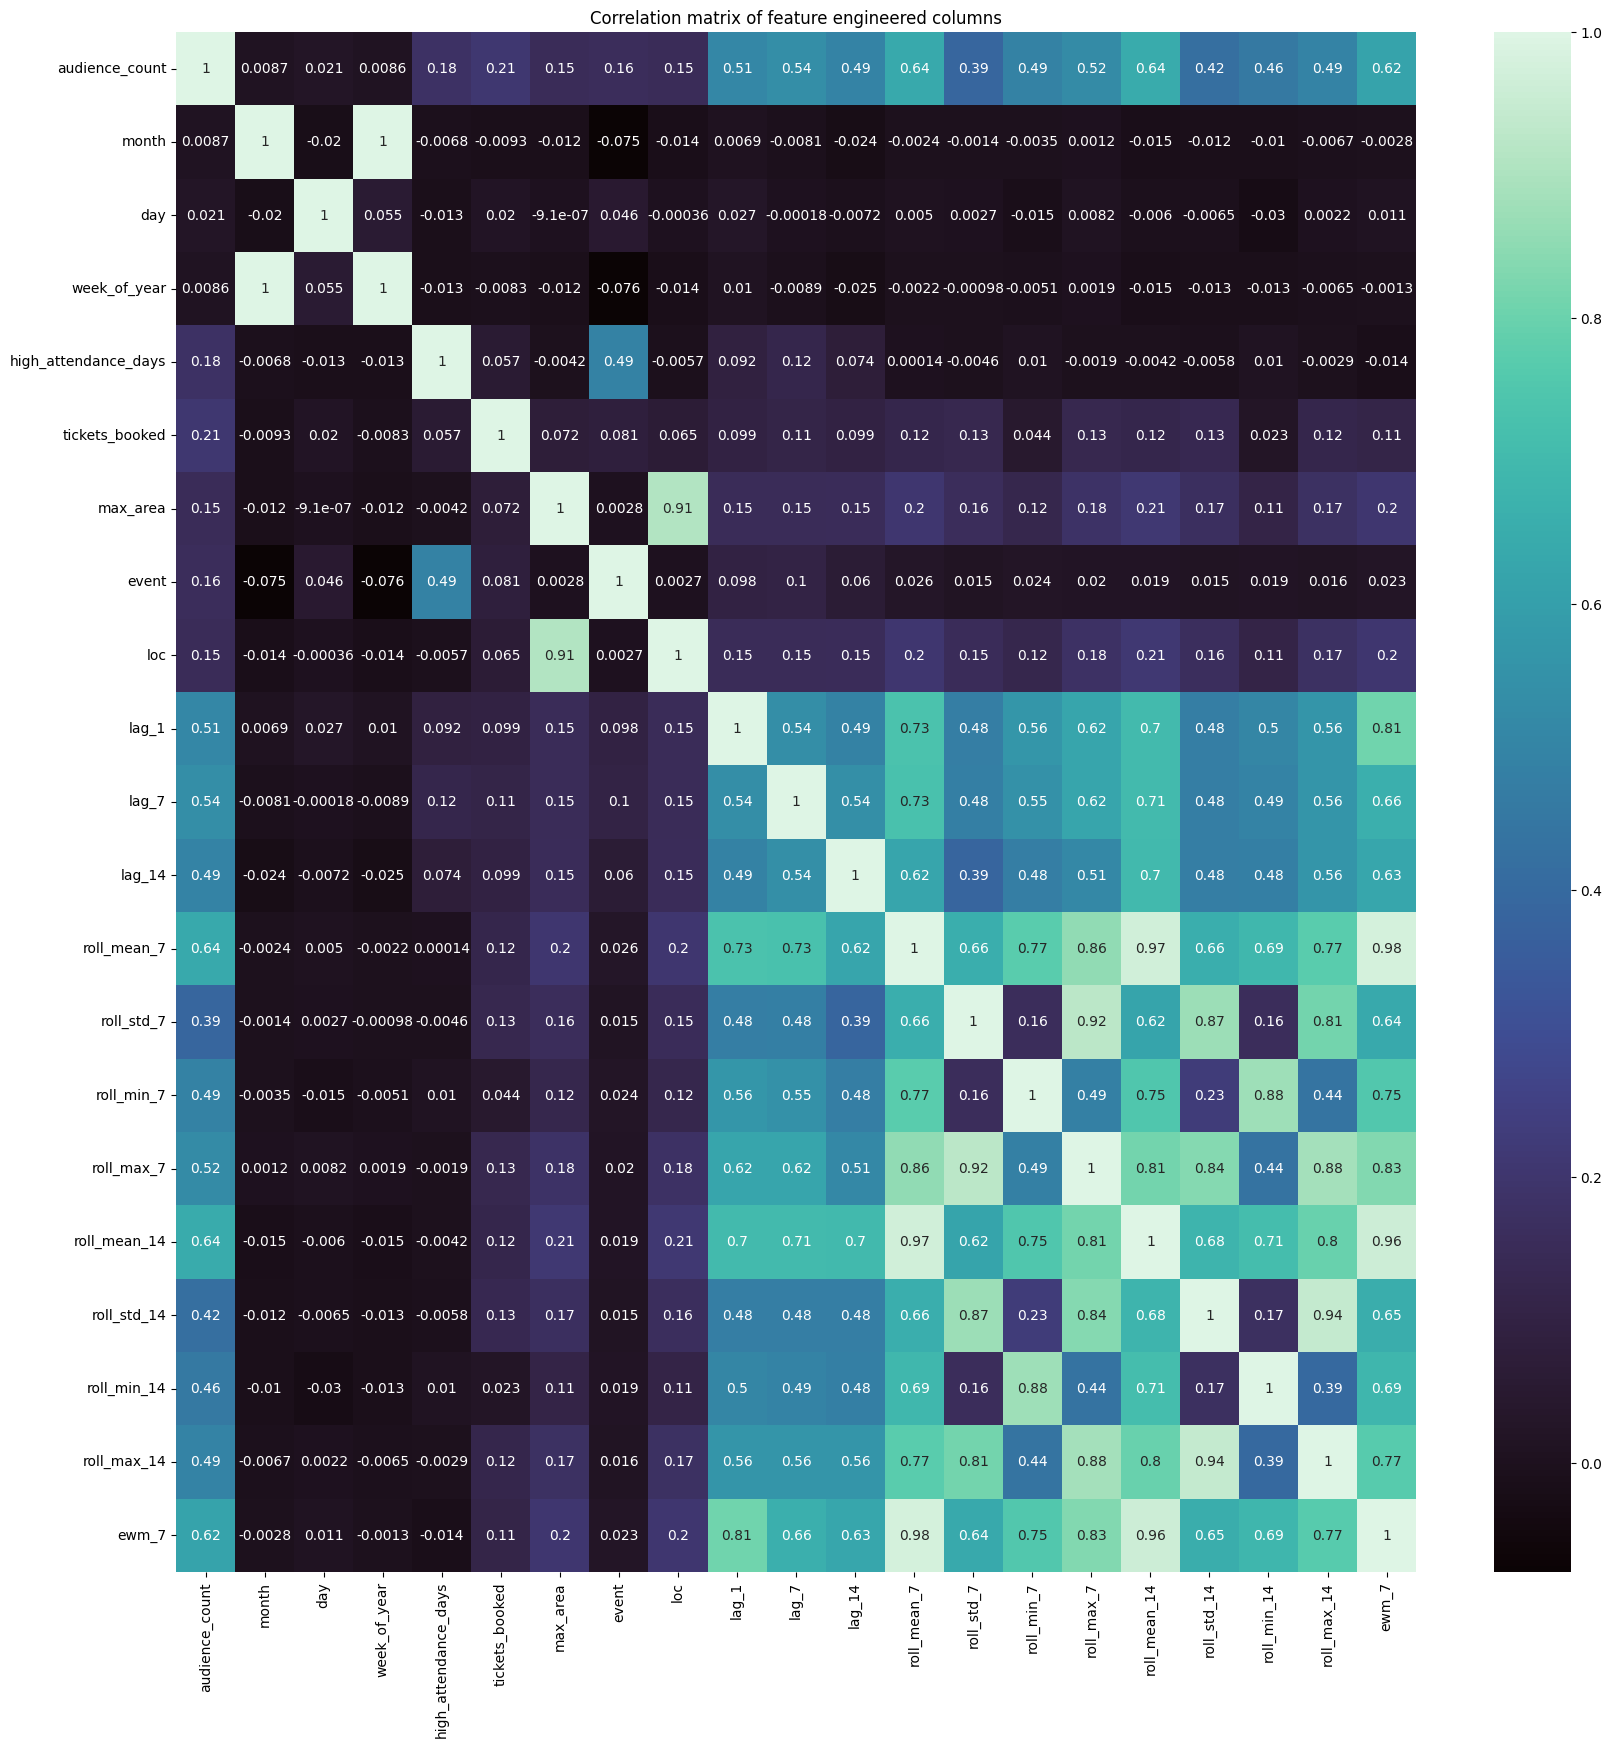

In [289]:
plt.figure(figsize=(20,20))
sns.heatmap(df_train_new.select_dtypes(include="number").corr(), annot=True, cmap="mako")
plt.title("Correlation matrix of feature engineered columns")
plt.show()

* Columns like high_attendance_days, event, tickets_booked, max_area has weak positive correlation with audience count.
* Majority of the lag, rolling and ewm features has positive correlation above 0.5 with audience count.

## Outliers in new columns:

In [290]:
features = []
outlier = []
for col in df_train_new.select_dtypes(include="number").columns:
    out = outliers(df_train_new, col)
    features.append(col)
    outlier.append(out)

data = pd.DataFrame({"Features": features, "Outliers": outlier})
data["Percent"] = round((data["Outliers"]/len(df_train_new))*100, 2).astype(str)+"%"

data

,Features,Outliers,Percent
0,audience_count,5589,2.61%
1,month,0,0.0%
2,day,0,0.0%
3,week_of_year,0,0.0%
4,high_attendance_days,0,0.0%
5,tickets_booked,27892,13.03%
6,max_area,14029,6.55%
7,event,0,0.0%
8,loc,16707,7.81%
9,lag_1,5581,2.61%


Due to presence of outliers in newly added feature engineered columns, I decided to use Robust scaler to handle the outliers.

# Scaling Numerical features and Encoding Categorical features:

In [291]:
from sklearn.preprocessing import RobustScaler, StandardScaler, OneHotEncoder, OrdinalEncoder, MinMaxScaler, MaxAbsScaler
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import PolynomialFeatures

# for Standard scaling
ss_cols = ["month", "day", "week_of_year"]

# for Robust scaling due to presence of outliers
robust_cols = ["tickets_booked", "lag_1", "lag_7", "lag_14", "roll_mean_7", "roll_std_7", "roll_min_7", "roll_max_7", "roll_mean_14", "roll_std_14", "roll_min_14", "roll_max_14", "ewm_7"]

# for OneHot Encoding
one_hot_cols = ["day_of_week", "theater_type"]

# for Ordinal encoding
ord_cols = ["theater_area", "Day_Month"]

# for passthrough because it is a binary column
pass_cols = ["high_attendance_days", "event", "max_area", "loc"]

ct = ColumnTransformer([
    ("sscaled", StandardScaler(), ss_cols),
    ("robust", RobustScaler(), robust_cols),
    ("ohe", OneHotEncoder(sparse_output=False, handle_unknown="ignore"), one_hot_cols),
    ("ord", OrdinalEncoder(categories=[theater_area_order, day_month_order]), ord_cols),
    ("pass", "passthrough", pass_cols)
], remainder="drop", verbose_feature_names_out=False).set_output(transform="pandas")

# Model building:

## Train-Test split:

In [292]:
from sklearn.model_selection import TimeSeriesSplit, cross_val_score, cross_validate

tss = TimeSeriesSplit(n_splits=5)

## Training and model comparison:

In [293]:
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import LinearSVR
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.linear_model import Ridge, SGDRegressor, LinearRegression
from sklearn.metrics import r2_score, mean_squared_error

In [294]:
models = {
    "Linear": LinearRegression(),
    "LightGBM": LGBMRegressor(random_state= 42),
    "Random Forest": RandomForestRegressor(random_state=42)
}

result=[]

for name, model in models.items():
    print(f"Training {name}........")
    if name in ["Linear", "Random Forest"]:
        main_model = Pipeline([
            ("transformer", ct),
            ("model", model)
        ])
    else:
        main_model = model
    
    cv_results = cross_val_score(main_model, X, y, cv=tss, scoring="r2")
    
    mean_result = cv_results.mean()

    result.append({
        "Model": name,
        "R2_score": mean_result
    })


df_result = pd.DataFrame(result)
df_result = df_result.sort_values("R2_score", ascending=False)
print("\n\n----------Model Comparison----------")
df_result

Training Linear........
Training LightGBM........
Training Random Forest........


----------Model Comparison----------


,Model,R2_score
1,LightGBM,0.496219
0,Linear,0.495338
2,Random Forest,0.491969


# Hyperparameter tuning:

## Random forest:

In [295]:
# from sklearn.model_selection import RandomizedSearchCV, GroupKFold
# from scipy.stats import randint, uniform

# rf_pipe = Pipeline([
#     ("preprocessor", ct),
#     ("model", RandomForestRegressor(random_state=42, n_jobs=-1))
# ]) 

# param_dist = {
#     "model__n_estimators": randint(200, 800),      # number of trees
#     "model__max_depth": randint(5, 40),            # tree depth
#     "model__min_samples_split": randint(2, 20),    # min samples to split
#     "model__min_samples_leaf": randint(1, 10),     # min leaf size
#     "model__max_features": ["auto", "sqrt", "log2"],
#     "model__bootstrap": [True, False]
# }

# cv = GroupKFold(n_splits=5)

# rf_search = RandomizedSearchCV(
#     estimator=rf_pipe,
#     param_distributions=param_dist,
#     n_iter=15,             
#     scoring="r2",
#     cv=cv,
#     n_jobs=-1,
#     verbose=2,
#     random_state=42
# )

# rf_search.fit(X, y, groups=df_train["book_theater_id"])

# print("Best R2 Score:", rf_search.best_score_)
# print("Best Parameters:", rf_search.best_params_)

# best_rf = rf_search.best_estimator_

# Best R2 Score: 0.5078815290260282
# Best Parameters: {'model__bootstrap': True, 'model__max_depth': 32, 'model__max_features': 'log2', 'model__min_samples_leaf': 3, 'model__min_samples_split': 13, 'model__n_estimators': 766}
# Best estimator: RandomForestRegressor(max_depth=32, 
#                                       max_features='log2', 
#                                       min_samples_leaf=3,
#                                       min_samples_split=13, 
#                                       n_estimators=766, 
#                                       n_jobs=-1,
#                                       random_state=42)

# Model submission:

In [296]:
# Fitting the model with the entire train data
final_model = RandomForestRegressor(max_depth=32, 
                                    max_features='log2', 
                                    min_samples_leaf=3,
                                    min_samples_split=13, 
                                    n_estimators=766, 
                                    n_jobs=-1,
                                    random_state=42)

pipe = Pipeline([
    ("preprocessor", ct),
    ("model", final_model)
])

pipe.fit(X, y)
y_pred = pipe.predict(test)

In [297]:
# Final submission

df_sample_submission["audience_count"] = y_pred

df_sample_submission.to_csv('submission.csv', index=False)

print("Submission file created successfully!")
print(df_sample_submission.head())

Submission file created successfully!
                      ID  audience_count
0  book_00001_2024-03-01       30.589137
1  book_00001_2024-03-02       40.340588
2  book_00001_2024-03-03       43.400271
3  book_00001_2024-03-04       38.779736
4  book_00001_2024-03-06       30.793838
